# How many measurements? The phase transition

"Sparse signals can be recovered from few measurements" is not a theorem
until *few* is a number. Theory (Candès et al., 2006; Donoho, 2006) says
that

$$m \;\gtrsim\; C\,k\,\log\!\frac{n}{k}$$

random measurements suffice for $\ell_1$ minimisation to recover a
$k$-sparse vector in $\mathbb{R}^n$ with overwhelming probability. Here $n$
is the length of the unknown vector, $k$ is its number of nonzeros, $m$ is
the number of measurements and $C$ is a constant. What the constant is, and
how sharp the threshold is, are empirical questions. The answer is one of
the most striking pictures in the field: a **phase transition** (Donoho and
Tanner). The $(k,m)$ plane splits into a region where recovery succeeds
essentially always and one where it fails essentially always, with a
knife-edge between them.

We measure it: $n=256$, a $12\times12$ grid of $(k,m)$, 20 independent
trials per cell, $\ell_1$ solved by our own FISTA with a least-squares
debiasing step.

**In this notebook you will**

* run 20 small recovery experiments in each cell of a $12\times12$ grid of
  $(k,m)$ and record the success rate in each cell;
* locate the 50% success level for each sparsity $k$ and fit the law
  $m_{50}=C\,k\log(n/k)$;
* check, with asserts, that the transition is sharp and that more
  measurements never hurt;
* read the resulting phase diagram.

**Before this notebook:** `cs_regularization`.
**Next:** `cs_recovery_fista`.
**Runtime:** about 40 s (almost all of it in the sweep of Section 1).

**Where the settings live.** This notebook has no separate parameter cell.
The grid and trial settings (`N`, `KS`, `MS`, `NTRIAL`, `SUCCESS_TOL`) are at
the top of the Section 1 code cell. The solver settings (number of FISTA
iterations `n_iter=800` and the penalty weight) are inside `l1_recover`.

The next cell loads NumPy, Matplotlib and the course plotting helpers
(`save_dual` writes a light and a dark version of the figure to
`../figures`).

In [1]:
import sys, os, time
sys.path.insert(0, os.path.abspath(os.path.join('..', '..')))
import numpy as np
import matplotlib.pyplot as plt
from pyutils import set_plot_style, save_dual, fg, muted
set_plot_style()

FIG = os.path.abspath(os.path.join('..', 'figures')); os.makedirs(FIG, exist_ok=True)

### The recovery solver

The measurement model is $\boldsymbol{y}=\boldsymbol{\Phi}\boldsymbol{s}$,
where $\boldsymbol{s}\in\mathbb{R}^n$ is the unknown sparse vector,
$\boldsymbol{\Phi}$ is the $m\times n$ measurement matrix and
$\boldsymbol{y}\in\mathbb{R}^m$ holds the $m$ measurements. The solver has
two stages.

1. **LASSO by FISTA.** `fista` minimises
   $\tfrac12\|\boldsymbol{\Phi}\boldsymbol{s}-\boldsymbol{y}\|_2^2+\lambda\|\boldsymbol{s}\|_1$.
   Each iteration takes a gradient step on the data term with step size
   $1/L$, where $L=\|\boldsymbol{\Phi}\|_2^2$ (the squared largest singular
   value), and then soft-thresholds at $\lambda/L$. The momentum variable
   $\boldsymbol{z}$ and the sequence $t$ make it converge much faster than
   the plain version (ISTA). The penalty is set small,
   $\lambda=0.005\max_j|(\boldsymbol{\Phi}^{\top}\boldsymbol{y})_j|$, so the
   data are fitted almost exactly.
2. **Debiasing.** The $\ell_1$ penalty shrinks the nonzero entries a little.
   `l1_recover` therefore keeps the $k$ largest entries of the FISTA result
   (the estimated support) and refits their values by ordinary least squares
   on those $k$ columns of $\boldsymbol{\Phi}$. If the support is right, the
   refit is exact.

The solver is told $k$, so success depends only on whether $\ell_1$ finds
the right support.

In [2]:
def soft_threshold(z, a):
    return np.sign(z)*np.maximum(np.abs(z) - a, 0.0)


def fista(Phi, y, lam, n_iter, L):
    s = np.zeros(Phi.shape[1]); z = s.copy(); t = 1.0
    for _ in range(n_iter):
        # gradient step on 0.5||Phi z - y||^2, then soft-threshold
        s_new = soft_threshold(z - (Phi.T @ (Phi @ z - y))/L, lam/L)
        t_new = 0.5*(1.0 + np.sqrt(1.0 + 4.0*t*t))
        z = s_new + ((t - 1.0)/t_new)*(s_new - s)   # momentum (extrapolation) step
        s, t = s_new, t_new
    return s


def l1_recover(Phi, y, k, n_iter=800):
    """LASSO by FISTA, then debias on the k largest coefficients."""
    L = np.linalg.norm(Phi, 2)**2                  # Lipschitz constant of the gradient
    lam = 0.005*np.max(np.abs(Phi.T @ y))
    s = fista(Phi, y, lam, n_iter, L)
    supp = np.argsort(np.abs(s))[-k:]              # indices of the k largest |s_j|
    out = np.zeros(Phi.shape[1])
    out[supp] = np.linalg.lstsq(Phi[:, supp], y, rcond=None)[0]
    return out

## 1. Sweep the $(k, m)$ plane

The settings at the top of the cell:

* `N` $=n=256$ is the signal length;
* `KS` holds the 12 sparsity levels $k=4,8,\dots,48$;
* `MS` holds the 12 measurement counts $m=16,32,\dots,192$;
* `NTRIAL` $=20$ is the number of independent trials per $(k,m)$ cell;
* `SUCCESS_TOL` $=10^{-2}$: a trial counts as a success when the relative
  error $\|\hat{\boldsymbol{s}}-\boldsymbol{s}\|_2/\|\boldsymbol{s}\|_2$ is
  below this value.

In each trial we draw a random support of $k$ positions, random signs and
magnitudes between 1 and 3 for the nonzeros of $\boldsymbol{s}$, and a
Gaussian matrix $\boldsymbol{\Phi}$ with entries of variance $1/m$. We
measure $\boldsymbol{y}=\boldsymbol{\Phi}\boldsymbol{s}$ (no noise), recover
$\hat{\boldsymbol{s}}$ and test the error. The array `rate[i, j]` stores the
success fraction for $k=$ `KS[i]` and $m=$ `MS[j]`. Each trial has its own
seed, so the run is reproducible. Cells with $k>m$ are skipped and keep
rate 0, since fewer equations than nonzeros can never pin down the values.

This cell takes about 40 s.

In [3]:
N = 256
KS = np.arange(4, 4 + 12*4, 4)          # 4, 8, ..., 48
MS = np.arange(16, 16 + 12*16, 16)      # 16, 32, ..., 192
NTRIAL = 20
SUCCESS_TOL = 1e-2                      # relative error counting as "recovered"

rate = np.zeros((KS.size, MS.size))
t0 = time.perf_counter()
for i, k in enumerate(KS):
    for j, m in enumerate(MS):
        if k > m:                        # trivially impossible
            continue
        hits = 0
        for trial in range(NTRIAL):
            rng = np.random.default_rng(1000*i + 10*j + trial)   # distinct seed per (cell, trial)
            supp = rng.choice(N, k, replace=False)
            s_true = np.zeros(N)
            s_true[supp] = rng.choice([-1.0, 1.0], k)*rng.uniform(1.0, 3.0, k)
            Phi = rng.standard_normal((m, N))/np.sqrt(m)       # columns have unit norm on average
            s_hat = l1_recover(Phi, Phi @ s_true, k)
            if np.linalg.norm(s_hat - s_true)/np.linalg.norm(s_true) < SUCCESS_TOL:
                hits += 1
        rate[i, j] = hits/NTRIAL
print(f"{KS.size}x{MS.size} grid x {NTRIAL} trials in {time.perf_counter()-t0:.1f} s")

12x12 grid x 20 trials in 40.0 s


The whole sweep ($12\times12$ cells, 20 trials each) took 40.0 s in the
reference run. Your time will differ with the machine.

## 2. Where is the edge?

For each sparsity $k$ we look along its row of `rate` for the first $m$
where the success rate reaches 0.5, and interpolate linearly between that
grid point and the one before it. This gives $m_{50}(k)$, the number of
measurements at which recovery succeeds half the time. If a row is not
cleanly below 0.5 and then above it, $m_{50}$ is set to NaN and left out of
the fit.

We then fit the theoretical form $m_{50}=C\,k\log(n/k)$. With
$p_k=k\log(n/k)$ (`pred`) this is a straight line through the origin, and
the least-squares slope is $C=\sum_k m_{50}(k)\,p_k/\sum_k p_k^2$. We also
report the RMS residual (in measurements) and the coefficient of
determination $R^2$ (1 means a perfect fit). The last line divides
$m_{50}$ by $k$: the number of measurements needed per nonzero.

In [4]:
m50 = []
for i, k in enumerate(KS):
    r = rate[i]
    lo = np.flatnonzero(r < 0.5)
    hi = np.flatnonzero(r >= 0.5)
    # need a clean crossing: all failures (<0.5) before all successes (>=0.5)
    if hi.size == 0 or lo.size == 0 or lo[-1] > hi[0]:
        m50.append(np.nan); continue
    j = hi[0]
    if j == 0:
        m50.append(float(MS[0])); continue
    f = (0.5 - r[j-1])/(r[j] - r[j-1])          # linear interpolation fraction
    m50.append(float(MS[j-1] + f*(MS[j] - MS[j-1])))
m50 = np.array(m50)

pred = KS*np.log(N/KS)
ok = np.isfinite(m50)
C = float(np.sum(m50[ok]*pred[ok])/np.sum(pred[ok]**2))
resid = np.sqrt(np.mean((m50[ok] - C*pred[ok])**2))
r2 = 1 - np.sum((m50[ok] - C*pred[ok])**2)/np.sum((m50[ok] - m50[ok].mean())**2)
print("k      :", KS)
print("m_50%  :", np.round(m50, 1))
print(f"fit m50 = C k log(n/k) with C = {C:.3f}  (RMS residual {resid:.1f} "
      f"measurements, R^2 = {r2:.3f})")
print(f"measurements per nonzero at the 50% line: "
      f"{np.round(m50[ok]/KS[ok], 2)}")

k      : [ 4  8 12 16 20 24 28 32 36 40 44 48]
m_50%  : [ 23.6  38.   49.6  62.   71.4  76.3  88.   98.7 103.1 113.5 117.7 126.2]
fit m50 = C k log(n/k) with C = 1.472  (RMS residual 4.2 measurements, R^2 = 0.982)
measurements per nonzero at the 50% line: [5.89 4.75 4.13 3.88 3.57 3.18 3.14 3.08 2.86 2.84 2.68 2.63]


Every row has a clean crossing, so all 12 values of $m_{50}$ are used. They
grow from 23.6 measurements at $k=4$ to 126.2 at $k=48$. The fit gives
$C=1.472$ with an RMS residual of 4.2 measurements and $R^2=0.982$, so the
$k\log(n/k)$ law describes the edge well. The ratio $m_{50}/k$ falls from
5.89 at $k=4$ to 2.63 at $k=48$: the logarithm $\log(n/k)$ shrinks as $k$
grows, so each nonzero needs fewer measurements. Around $k=16$ to $k=20$
the ratio is 3.88 to 3.57, close to the rule of thumb of three to five
measurements per nonzero.

## 3. Checking the claims

The next cell turns the main statements of this notebook into asserts:

* deep in the success region ($k=8$, $m=128$) recovery works at least 95%
  of the time;
* deep in the failure region ($k=44$, $m=48$) it works at most 5% of the
  time;
* the transition is sharp: for $k=20$ the range of $m$ between the last
  point with under 5% success and the first point with at least 95% success
  is at most 64 measurements;
* the success rate grows with $m$ in every row, allowing dips of up to 0.15
  from trial noise;
* the fitted constant satisfies $1<C<4$, and the fit has $R^2>0.9$.

In [5]:
# deep in the success region
i_easy, j_easy = int(np.flatnonzero(KS == 8)[0]), int(np.flatnonzero(MS == 128)[0])
print(f"k=8,  m=128: success rate {rate[i_easy, j_easy]:.2f}")
assert rate[i_easy, j_easy] >= 0.95

# deep in the failure region
i_hard, j_hard = int(np.flatnonzero(KS == 44)[0]), int(np.flatnonzero(MS == 48)[0])
print(f"k=44, m=48 : success rate {rate[i_hard, j_hard]:.2f}")
assert rate[i_hard, j_hard] <= 0.05

# the transition is sharp: at fixed k, a modest increase in m flips the outcome
i = int(np.flatnonzero(KS == 20)[0])
j_lo = int(np.flatnonzero(rate[i] >= 0.05)[0]) - 1
j_hi = int(np.flatnonzero(rate[i] >= 0.95)[0])
print(f"k=20: success <5% at m={MS[max(j_lo,0)]}, >95% at m={MS[j_hi]} "
      f"-> the whole transition spans {MS[j_hi]-MS[max(j_lo,0)]} measurements")
assert MS[j_hi] - MS[max(j_lo, 0)] <= 64, "the transition must be sharp"

# monotone in m (more measurements never hurt), within trial noise
for i in range(KS.size):
    assert np.all(np.diff(rate[i]) >= -0.15), "success rate must increase with m"

assert 1.0 < C < 4.0, "the empirical constant should be O(1)"
assert r2 > 0.9, "the k log(n/k) law must explain the measured 50% line"

k=8,  m=128: success rate 1.00
k=44, m=48 : success rate 0.00
k=20: success <5% at m=48, >95% at m=96 -> the whole transition spans 48 measurements


All asserts pass. At $k=8$, $m=128$ every trial succeeds (rate 1.00); at
$k=44$, $m=48$ every trial fails (rate 0.00). For $k=20$ the success rate is
below 5% at $m=48$ and above 95% at $m=96$, so the whole transition fits
inside 48 measurements, out of a signal of length 256.

## 4. The phase diagram

The next cell draws two panels. The left panel is the full success-rate
map `rate` with the measured $m_{50}$ points and the fitted curve
$m=C\,k\log(n/k)$ on top. The right panel shows rows of the map for
$k=8,20,32,44$ as success rate against $m$.

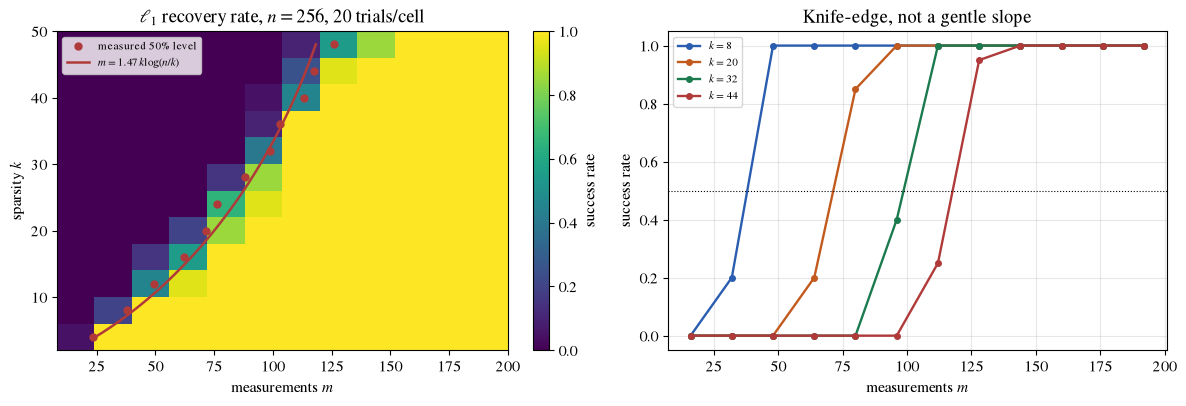

In [6]:
def plot_phase():
    fig, ax = plt.subplots(1, 2, figsize=(12, 4.2))
    im = ax[0].imshow(rate, origin='lower', aspect='auto', cmap='viridis',
                      vmin=0, vmax=1,
                      extent=[MS[0]-8, MS[-1]+8, KS[0]-2, KS[-1]+2])
    ax[0].plot(m50, KS, 'o', color='C3', ms=5, label='measured 50% level')
    kfine = np.linspace(KS[0], KS[-1], 200)
    ax[0].plot(C*kfine*np.log(N/kfine), kfine, color='C3', lw=1.8,
               label=f'$m={C:.2f}\\,k\\log(n/k)$')
    ax[0].set(xlabel='measurements $m$', ylabel='sparsity $k$',
              title=f'$\\ell_1$ recovery rate, $n={N}$, {NTRIAL} trials/cell')
    ax[0].set_xlim(MS[0]-8, MS[-1]+8); ax[0].set_ylim(KS[0]-2, KS[-1]+2)
    ax[0].legend(fontsize=8, loc='upper left')
    ax[0].grid(False)
    cb = fig.colorbar(im, ax=ax[0], fraction=0.046)
    cb.set_label('success rate')
    for i, k in enumerate(KS):
        if k in (8, 20, 32, 44):
            ax[1].plot(MS, rate[i], 'o-', lw=1.7, ms=4, label=f'$k={k}$')
    ax[1].axhline(0.5, color=fg(), lw=0.8, ls=':')
    ax[1].set(xlabel='measurements $m$', ylabel='success rate',
              title='Knife-edge, not a gentle slope', ylim=(-0.05, 1.05))
    ax[1].legend(fontsize=8)
    plt.tight_layout()


save_dual(plot_phase, 'cs_phase', FIG)
plt.show()

**How to read this figure.**
*Left panel:* each coloured cell is one $(k,m)$ pair, with the number of
measurements $m$ on the horizontal axis (16 to 192) and the sparsity $k$
on the vertical axis (4 to 48). The colour is the success rate over 20
trials: dark purple is 0 (every trial failed), yellow is 1 (every trial
succeeded), see the colour bar. The cells in the top-left corner with
$k>m$ were skipped and also show as 0. Red dots are the measured 50% levels
$m_{50}(k)$; the red line is the fit $m=1.47\,k\log(n/k)$.
*Right panel:* four rows of the left map ($k=8,20,32,44$, one colour each)
plotted as success rate against $m$. The dotted horizontal line marks a
success rate of 0.5.

**What it shows.** The left map is split into two nearly uniform regions:
yellow (recovery works) below and to the right, purple (recovery fails)
above and to the left. The band of intermediate colours between them is
only one or two cells wide. The red dots follow the fitted curve closely
($R^2=0.982$), so the edge really does grow like $k\log(n/k)$, slightly
slower than linearly in $k$. The right panel shows the same sharpness one
row at a time. Each curve sits at 0, then jumps to 1 within a few grid
steps; for $k=20$ the jump happens between $m=48$ and $m=96$. Larger $k$
shifts the jump to the right but does not make it gentler.

The practical message: if you know roughly how sparse the signal is, you
can read off how many random measurements you need, and adding a modest
safety margin above the red line moves you from unreliable to reliable.

## Summary

* Recovery is not a matter of degree: at fixed $k$ the success rate goes
  from near zero to near one over a narrow band of $m$ (48 measurements for
  $k=20$). This is the Donoho–Tanner phase transition. It is why compressed
  sensing can be *engineered*: you can budget sensors against a target
  sparsity.
* The measured 50% line follows $m\approx C\,k\log(n/k)$ with $C=1.472$ and
  $R^2=0.982$, an $O(1)$ constant and exactly the scaling the theory
  predicts. The folk rule "three to five measurements per nonzero" is what
  this curve says at moderate $k$ (3.88 at $k=16$, 3.57 at $k=20$).
* Read the failure side honestly: below the line $\ell_1$ does not degrade
  gracefully, it returns a confidently wrong answer. Undersampling is not a
  bias-variance trade-off. It is a cliff.

## Try this

The grid and trial settings are at the top of the Section 1 code cell; the
solver settings are in `l1_recover`. Rerun the whole notebook after each
change.

1. **Fewer trials.** Set `NTRIAL = 10`. The run takes about half as long.
   The success rates are coarser (steps of 0.1), so the red dots scatter a
   little more around the fitted curve, but $C$ and the overall picture stay
   about the same.
2. **A longer signal.** Set `N = 512` (keep `KS` and `MS`). The edge moves
   to the right, because $\log(n/k)$ is larger: each $k$ needs more
   measurements. The fitted $C$ stays of order one.
3. **A weaker solver.** In `l1_recover`, change `n_iter=800` to
   `n_iter=100`. The run is much faster, but FISTA has not converged, so it
   picks the wrong support more often and the edge moves to larger $m$
   (larger $C$), most visibly at small $k$.
4. **A looser success test.** Set `SUCCESS_TOL = 1e-1`. Almost nothing
   changes. Thanks to the debiasing step a trial either finds the right
   support and is recovered essentially exactly, or misses it and is far
   off. There is little in between.